# Player Value & Retention Engine: results

Who should get a retention offer, and who must never get one?

This notebook tells the story of the project in eight charts. Everything is **synthetic data**, built to behave like an online betting operator, with harm signals based on retail safer gambling practice. The pipeline itself lives in `src/` and `sql/`; this notebook only reads its outputs.

To re-run it: `make pipeline` and `python -m pve.monitor` first, then run all cells.

In [1]:
import json, os
from pathlib import Path

if Path.cwd().name == "notebooks":          # run from the repo root
    os.chdir(Path.cwd().parent)

import duckdb
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from sklearn.model_selection import train_test_split

from pve import impact
from pve.scoring import score_players
from pve.train_baselines import load

# chart style: thin marks, quiet axes, one colour that matters
BLUE, ORANGE, GREY = "#2a78d6", "#eb6834", "#a3a29b"
INK, MUTED = "#0b0b0b", "#52514e"
plt.rcParams.update({
    "figure.dpi": 110, "figure.facecolor": "white", "axes.facecolor": "white",
    "font.size": 11, "axes.titlesize": 13, "axes.titleweight": "bold", "axes.titlelocation": "left",
    "axes.edgecolor": "#d6d5cf", "axes.labelcolor": MUTED, "xtick.color": MUTED, "ytick.color": MUTED,
    "axes.spines.top": False, "axes.spines.right": False, "axes.grid": False, "text.color": INK,
})
pd.set_option("display.float_format", lambda v: f"{v:,.0f}")

metrics = json.loads(Path("reports/model_metrics.json").read_text())
players = pd.read_parquet("data/raw/players.parquet")
features = pd.read_parquet("data/features/player_features.parquet")

# the same current players and test split the models were judged on
df = load()
_, test = train_test_split(df, test_size=0.3, random_state=42, stratify=df["churned_90d"])
test = test.reset_index(drop=True)
scores = score_players(test, Path("models"))
scores["churned"] = test["churned_90d"].astype(bool).to_numpy()
scores["in_harm"] = test["_in_harm"].to_numpy()
N_OFFERS = len(scores) // 10
print(f"{len(df):,} current players; {len(test):,} in the test set; budget of {N_OFFERS} offers (10%)")

6,940 current players; 2,082 in the test set; budget of 208 offers (10%)


## 1. What harm looks like for one player

A real at-risk player from the data. For months they bet small amounts on their usual market. Then, at a hidden *harm onset* date, their stakes jump, they move into markets they never used, and they keep escalating.

Player 7196: median stake before onset £2.79, after £35.12; usual market 88% of bets before, 41% after


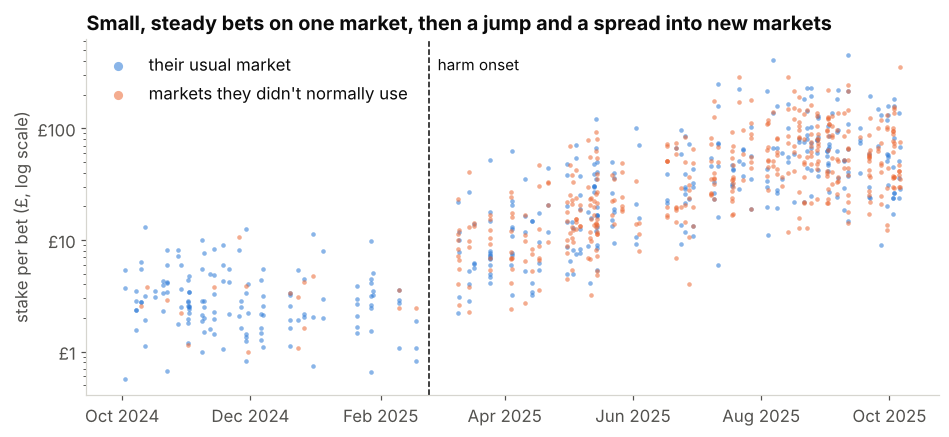

In [2]:
# pick a clear example: small bets for months, then a long stretch after onset
example = duckdb.sql("""
    WITH b AS (
        SELECT b.player_id, b.placed_at, b.stake, p._harm_onset_date AS onset
        FROM 'data/raw/bets.parquet' b JOIN 'data/raw/players.parquet' p USING (player_id)
        WHERE p._harm_onset_date IS NOT NULL)
    SELECT player_id
    FROM b
    GROUP BY player_id
    HAVING SUM((placed_at <  onset)::INT) BETWEEN 120 AND 500
       AND SUM((placed_at >= onset)::INT) BETWEEN 150 AND 700
       AND MEDIAN(stake) FILTER (WHERE placed_at < onset) <= 6
       AND MAX(placed_at) - MIN(onset) > INTERVAL 100 DAY
    ORDER BY MEDIAN(stake) FILTER (WHERE placed_at >= onset)
           / MEDIAN(stake) FILTER (WHERE placed_at < onset) DESC, player_id
    LIMIT 1
""").fetchall()[0][0]
bets = duckdb.sql(f"""
    SELECT b.placed_at, b.stake, b.market = p.home_market AS home, p._harm_onset_date AS onset
    FROM 'data/raw/bets.parquet' b JOIN 'data/raw/players.parquet' p USING (player_id)
    WHERE player_id = {example}
""").df()
onset = bets["onset"].iloc[0]

fig, ax = plt.subplots(figsize=(10, 4.2))
for home, colour, label in [(True, BLUE, "their usual market"), (False, ORANGE, "markets they didn't normally use")]:
    d = bets[bets["home"] == home]
    ax.scatter(d["placed_at"], d["stake"], s=9, color=colour, alpha=0.55, linewidths=0, label=label)
ax.axvline(onset, color=INK, lw=1, ls="--")
ax.set_yscale("log")
ax.text(onset, bets["stake"].max(), "  harm onset", va="top", color=INK, fontsize=10)
import matplotlib.dates as mdates
ax.xaxis.set_major_locator(mdates.MonthLocator(interval=2))
ax.xaxis.set_major_formatter(mdates.DateFormatter("%b %Y"))
ax.yaxis.set_major_formatter(lambda v, _: f"£{v:g}")
ax.set_ylabel("stake per bet (£, log scale)")
ax.set_title("Small, steady bets on one market, then a jump and a spread into new markets")
ax.legend(frameon=False, loc="upper left", markerscale=2)
before, after = bets[bets["placed_at"] < onset], bets[bets["placed_at"] >= onset]
print(f"Player {example}: median stake before onset £{before.stake.median():.2f}, after £{after.stake.median():.2f}; "
      f"usual market {before.home.mean():.0%} of bets before, {after.home.mean():.0%} after")
plt.show()

## 2. Harm is a change from a player's own normal

The key insight from the shop floor: a big stake is not a warning sign by itself, but a **change** is. Comparing each player's recent average stake with **their own first month** separates harmed players from everyone else, including big-spending VIPs and "upgraders" whose stakes rise slowly for healthy reasons.

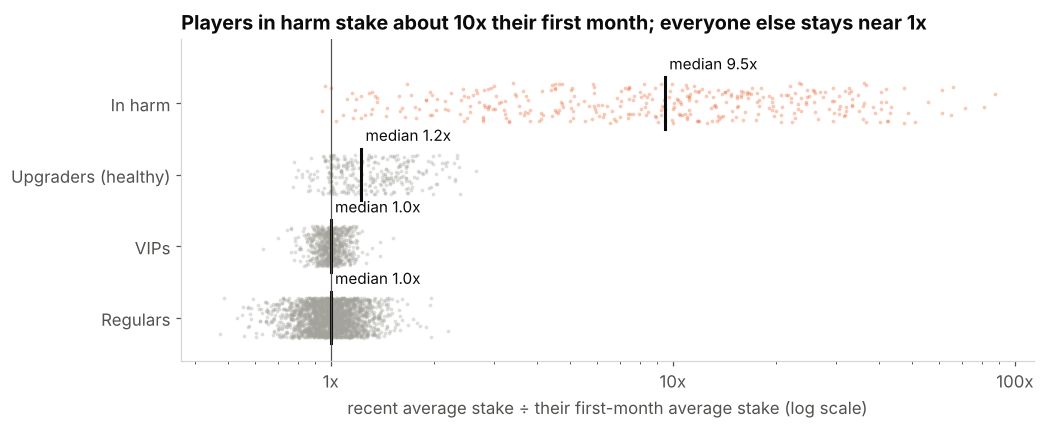

In [3]:
f = features.merge(players[["player_id", "_true_segment", "_harm_onset_date", "_upgrader"]], on="player_id")
f = f[f["active_days_30d"] > 0].copy()
f["group"] = np.select(
    [f["_harm_onset_date"].notna() & (f["_harm_onset_date"] <= f["snapshot_date"]),
     f["_upgrader"], f["_true_segment"] == "vip", f["_true_segment"] == "regular"],
    ["In harm", "Upgraders (healthy)", "VIPs", "Regulars"], default=None)
f = f[f["group"].notna() & f["stake_vs_first30"].notna()]
order = ["Regulars", "VIPs", "Upgraders (healthy)", "In harm"]

fig, ax = plt.subplots(figsize=(10, 3.8))
rng = np.random.default_rng(0)
for i, g in enumerate(order):
    v = f.loc[f["group"] == g, "stake_vs_first30"].clip(0.1, 200)
    colour = ORANGE if g == "In harm" else GREY
    ax.scatter(v, i + rng.uniform(-0.28, 0.28, len(v)), s=6, color=colour, alpha=0.35, linewidths=0)
    ax.plot([v.median()] * 2, [i - 0.36, i + 0.36], color=INK, lw=2)
    ax.text(v.median(), i + 0.42, f" median {v.median():.1f}x", fontsize=10, color=INK, va="bottom")
ax.axvline(1, color=MUTED, lw=0.8)
ax.set_xscale("log")
ax.xaxis.set_major_formatter(lambda v, _: f"{v:g}x")
ax.set_yticks(range(len(order)), order)
ax.set_ylim(-0.6, len(order) - 0.1)
ax.set_xlabel("recent average stake ÷ their first-month average stake (log scale)")
ax.set_title("Players in harm stake about 10x their first month; everyone else stays near 1x")
plt.show()

## 3. The problem: value models target harmed players

A value model is built to find players who will spend the most. Escalating stakes look like high value, so the players it ranks highest include a disproportionate share of players in harm.

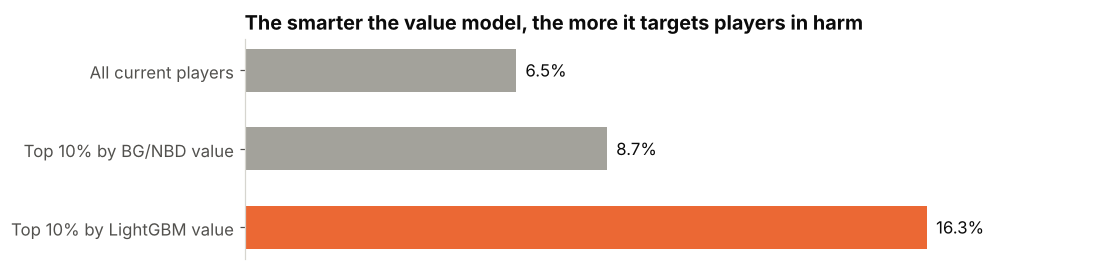

In [4]:
base = scores["in_harm"].mean()
top_bg = impact.pick(scores, "predicted_value_6m", N_OFFERS, guardrail=False)["in_harm"].mean()
top_lgb = metrics["offers"]["harmed_share_without_guardrail"]
rows = [("All current players", base), ("Top 10% by BG/NBD value", top_bg), ("Top 10% by LightGBM value", top_lgb)]

fig, ax = plt.subplots(figsize=(10, 2.6))
for i, (label, v) in enumerate(rows):
    ax.barh(i, v, color=ORANGE if i == 2 else GREY, height=0.55)
    ax.text(v, i, f"  {v:.1%}", va="center", color=INK)
ax.set_yticks(range(len(rows)), [r[0] for r in rows])
ax.invert_yaxis()
ax.set_xlim(0, max(v for _, v in rows) * 1.25)
ax.set_xticks([])
ax.spines["bottom"].set_visible(False)
ax.set_title("The smarter the value model, the more it targets players in harm")
plt.show()

## 4. The safer gambling guardrail

Harm is checked first, always:

| Decision | Trigger | Action |
|---|---|---|
| Suspended | Source-of-funds check failed or not provided | No betting until documents are provided |
| Red | Harm model flag **and** 3+ retail warning signs | No offers; customer contact, self-exclusion offered if needed |
| Amber | Harm model flag, **or** lifetime stake 2x+ their first month | No promotional or retention offers |
| Eligible | Good betting history and no concerns | May receive retention offers |

The trade-off is set on purpose: missing a harmed player is worse than withholding an offer from a healthy VIP.

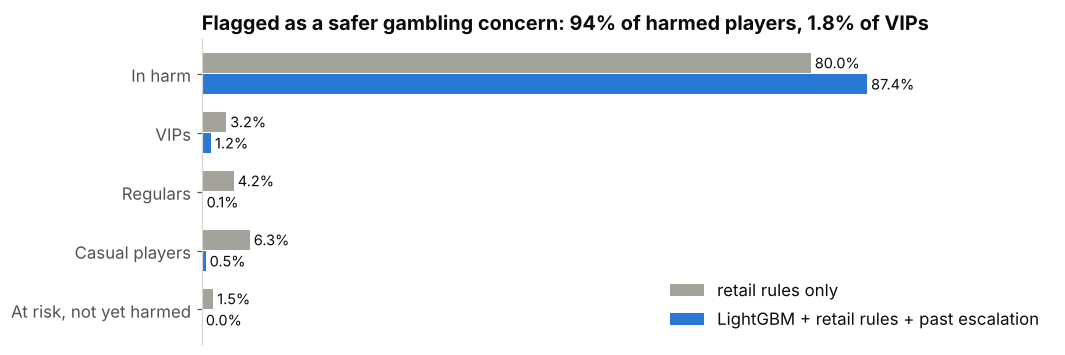

Offers to harmed players (top 10% by LightGBM value): 34 without the guardrail, 3 with it


In [5]:
groups = {"at_risk_in_harm": "In harm", "vip": "VIPs", "regular": "Regulars",
          "casual": "Casual players", "at_risk": "At risk, not yet harmed"}
rules = metrics["harm"]["rules_only"]["share_flagged_by_group"]
model = metrics["harm"]["model_plus_rules"]["share_flagged_by_group"]

fig, ax = plt.subplots(figsize=(10, 3.6))
y = np.arange(len(groups))
for off, data, colour, label in [(-0.18, rules, GREY, "retail rules only"),
                                 (0.18, model, BLUE, "LightGBM + retail rules + past escalation")]:
    vals = [data.get(k, 0) for k in groups]
    ax.barh(y + off, vals, height=0.34, color=colour, label=label)
    for yi, v in zip(y + off, vals):
        ax.text(v, yi, f" {v:.1%}", va="center", fontsize=9.5, color=INK)
ax.set_yticks(y, list(groups.values()))
ax.invert_yaxis()
ax.set_xlim(0, 1.12)
ax.set_xticks([])
ax.spines["bottom"].set_visible(False)
ax.legend(frameon=False, loc="lower right")
ax.set_title("Flagged as a safer gambling concern: 94% of harmed players, 1.8% of VIPs")
plt.show()

o = metrics["offers"]
print(f"Offers to harmed players (top 10% by LightGBM value): "
      f"{o['harmed_players_offered_without_guardrail']} without the guardrail, "
      f"{o['harmed_players_offered_with_guardrail']} with it")

## 5. Who gets the offers: value vs value at risk

A valuable player who will stay anyway doesn't need an offer. Ranking eligible players by **value at risk** (value if retained x chance of churning) sends offers to the players an offer can actually save.

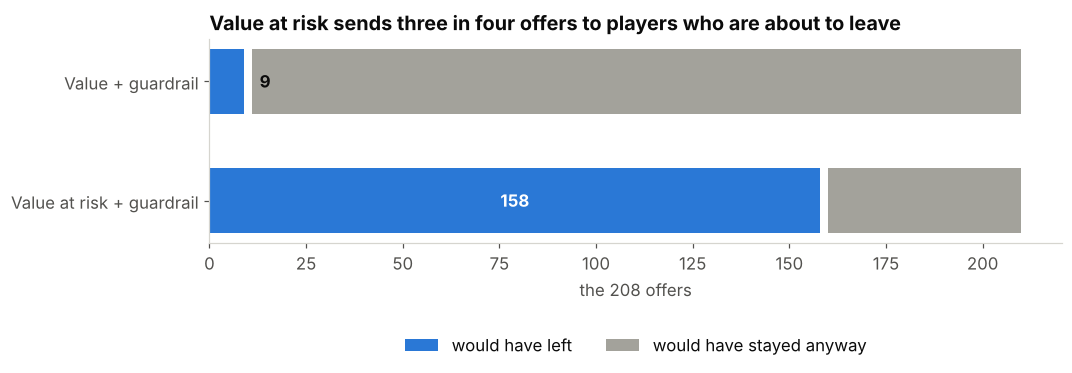

In [6]:
strategies = {
    "Value + guardrail": impact.pick(scores, "predicted_value_6m", N_OFFERS, guardrail=True),
    "Value at risk + guardrail": impact.pick(scores, "value_at_risk", N_OFFERS, guardrail=True),
}
fig, ax = plt.subplots(figsize=(10, 2.4))
for i, (name, t) in enumerate(strategies.items()):
    leave, stay = int(t["churned"].sum()), int((~t["churned"]).sum())
    ax.barh(i, leave, color=BLUE, height=0.55, label="would have left" if i == 0 else None)
    ax.barh(i, stay, left=leave + 2, color=GREY, height=0.55, label="would have stayed anyway" if i == 0 else None)
    ax.text(leave / 2 if leave > 25 else leave + 4, i, f"{leave}", va="center",
            ha="center" if leave > 25 else "left", color="white" if leave > 25 else INK, fontweight="bold")
ax.set_yticks([0, 1], list(strategies))
ax.invert_yaxis()
ax.set_xlabel(f"the {N_OFFERS} offers")
ax.legend(frameon=False, loc="upper center", bbox_to_anchor=(0.5, -0.38), ncol=2)
ax.set_title("Value at risk sends three in four offers to players who are about to leave")
plt.show()

## 6. Commercial impact

What churn costs, what each campaign saves, and what it costs. Two assumptions, stated plainly because a real operator would measure them with a controlled test:

- an offer keeps **{:.0%}** of the would-be leavers it reaches;
- each offer costs **£{:.0f}** (e.g. a free bet).

Value is each player's recent run rate (last 90 days' stake x house margin) over the next 6 months.

Without any campaign, the 728 players who leave (of 2,082) take £426,324 of 6-month value with them (12% of all player value).


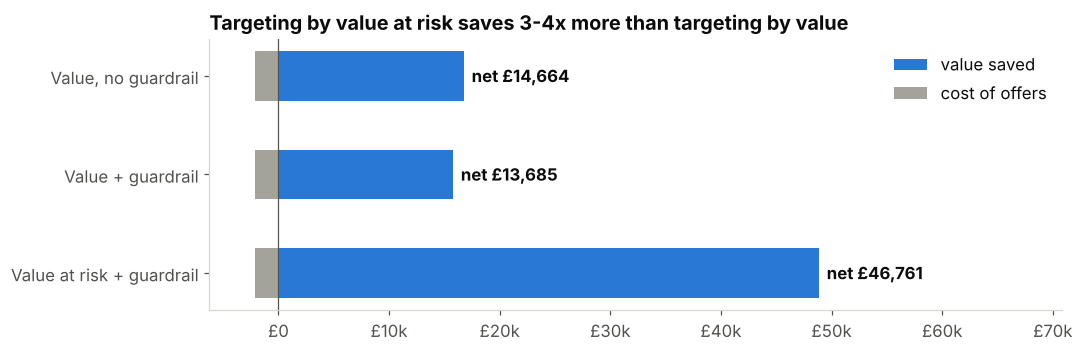

,offers_to_players_who_would_leave,offers_to_harmed_players,value_saved,value_saved_from_harmed_players,offer_cost,net_impact
"Value, no guardrail",8,18,"16,744","2,114","2,080","14,664"
Value + guardrail,9,0,"15,765",0,"2,080","13,685"
Value at risk + guardrail,158,3,"48,841",303,"2,080","46,761"


In [7]:
cost = impact.churn_cost(scores)
print(f"Without any campaign, the {cost['churners']:,} players who leave (of {cost['players']:,}) "
      f"take £{cost['value_lost_to_churn']:,.0f} of 6-month value with them "
      f"({cost['value_lost_to_churn'] / cost['value_of_all_players']:.0%} of all player value).")

table = impact.compare_strategies(scores, N_OFFERS)
fig, ax = plt.subplots(figsize=(10, 3.2))
y = np.arange(len(table))
ax.barh(y, table["value_saved"], color=BLUE, height=0.5, label="value saved")
ax.barh(y, -table["offer_cost"], color=GREY, height=0.5, label="cost of offers")
for yi, (_, r) in zip(y, table.iterrows()):
    ax.text(r["value_saved"], yi, f"  net £{r['net_impact']:,.0f}", va="center", color=INK, fontweight="bold")
ax.axvline(0, color=MUTED, lw=0.8)
ax.set_yticks(y, table.index)
ax.invert_yaxis()
ax.set_xlim(-table["offer_cost"].max() * 3, table["value_saved"].max() * 1.45)
ax.xaxis.set_major_formatter(lambda v, _: f"£{abs(v)/1000:.0f}k" if v else "£0")
ax.legend(frameon=False, loc="upper right")
ax.set_title("Targeting by value at risk saves 3-4x more than targeting by value")
plt.show()

table[["offers_to_players_who_would_leave", "offers_to_harmed_players", "value_saved",
       "value_saved_from_harmed_players", "offer_cost", "net_impact"]]

**Does the conclusion depend on the assumptions?** Net impact of the guarded value-at-risk campaign under different assumptions. It stays clearly positive in every case.

In [8]:
impact.sensitivity(scores, N_OFFERS)

,£5 per offer,£10 per offer,£25 per offer
saves 10% of leavers,"23,380","22,340","19,220"
saves 20% of leavers,"47,801","46,761","43,641"
saves 30% of leavers,"72,221","71,181","68,061"


**What the guardrail gives up.** Without the guardrail, part of the "value saved" would come from keeping players in harm betting. The guardrail gives that up on purpose: it is revenue an operator should not want, and it carries regulatory and reputational risk.

## 7. Why a player gets flagged

Every flag must be explainable to a customer, a colleague or a regulator. SHAP shows which features drive the harm model overall, and the scoring API returns plain-English reasons for each player.

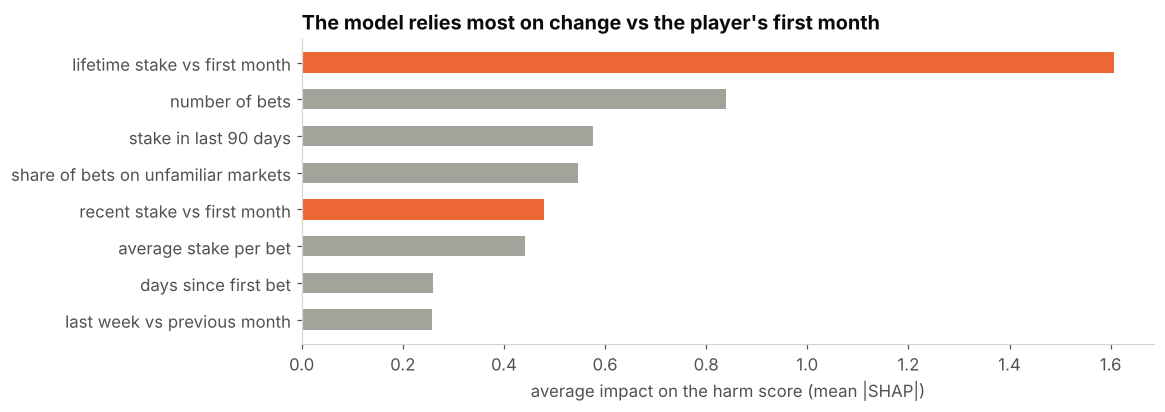

Example red flag, player 11915:
  - Harm model score 1.0000 (flagged from 0.9996)
  - Recent stakes are 12.7x their first month
  - 52% of recent bets are on markets they didn't use at first
  - Late-night betting is up 27 percentage points on their first month
  - 8 declined deposits in the last 30 days
  - Sessions are 1.7x longer than in their first month
  - Lifetime average stake is 6.7x their first month (past escalation)


In [9]:
names = {
    "stake_lifetime_vs_first30": "lifetime stake vs first month",
    "stake_vs_first30": "recent stake vs first month",
    "total_bets": "number of bets",
    "stake_90d": "stake in last 90 days",
    "unfamiliar_share_30d": "share of bets on unfamiliar markets",
    "latest_stake_jump_ratio": "last week vs previous month",
    "late_share_vs_first30": "late-night betting vs first month",
    "avg_stake_per_bet": "average stake per bet",
    "total_stake": "total stake",
    "failed_deposits_30d": "declined deposits (30 days)",
    "stake_30d": "stake in last 30 days",
    "tenure_days": "days since first bet",
    "bets_30d": "bets in last 30 days",
    "active_days": "days with a bet",
    "session_minutes_30d": "session length (30 days)",
    "recency_days": "days since last bet",
}
top = pd.Series(metrics["harm_top_features"]).head(8)[::-1]
fig, ax = plt.subplots(figsize=(10, 3.6))
ax.barh([names.get(k, k) for k in top.index], top.values,
        color=[ORANGE if "first month" in names.get(k, "") else GREY for k in top.index], height=0.55)
ax.set_xlabel("average impact on the harm score (mean |SHAP|)")
ax.set_title("The model relies most on change vs the player's first month")
plt.show()

red = scores[scores["decision"] == "red"].sort_values("harm_score", ascending=False).iloc[0]
print(f"Example red flag, player {red.player_id}:")
for r in red.reasons:
    print("  -", r)

## 8. Is the model still working? Drift monitoring

The models learned from players as of 30 June 2025. Every month after that, `src/pve/monitor.py` re-scores current players with the same models and checks whether the players, the scores or the accuracy have changed. **PSI** (Population Stability Index) measures how far a feature has moved from the training month: under 0.1 is stable, 0.1-0.25 is worth watching, over 0.25 is an alert.

To test it, a "what-if" copy of the data adds two real-world events after training:
- **a new virtuals game** in October: many players try it out for a few weeks;
- **a winter football tournament** (20 Nov - 18 Dec): extra football bets, including from players who normally bet on racing.

Healthy players try new things for a few weeks, then go back to their usual market. "Bets on markets they don't normally use" is one of the strongest harm signals, so this is exactly the kind of event that could fool a safer gambling model.

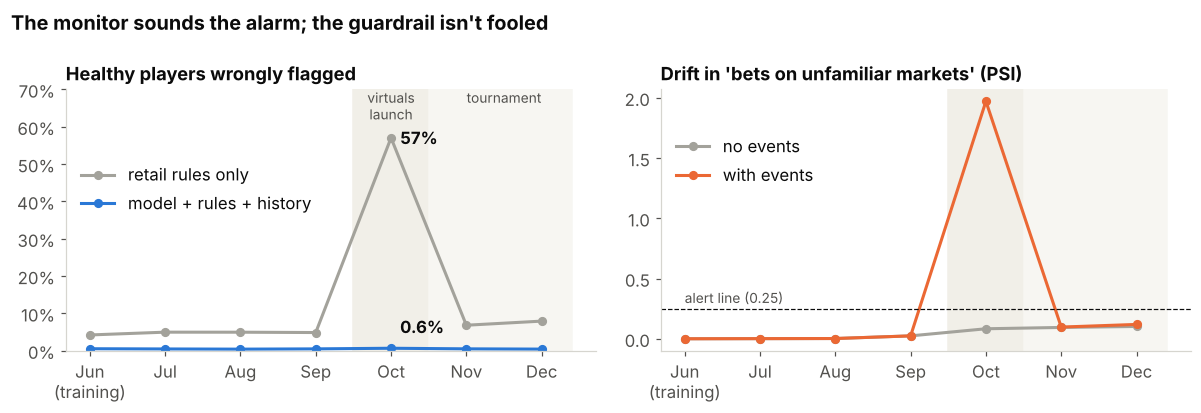

,status,current players,flagged,churn ROC-AUC,features drifting
month end,,,,,
2025-06-30,stable,6940,7.0%,0.989,-
2025-07-31,stable,6988,6.5%,0.956,-
2025-08-31,stable,7051,6.4%,0.960,-
2025-09-30,stable,6504,7.2%,0.967,-
2025-10-31,alert,5676,8.6%,not known yet,"stake_vs_first30, unfamiliar_share_30d, sessio..."
2025-11-30,alert,4810,9.5%,not known yet,"stake_30d, bets_30d, stake_vs_first30, latest_..."
2025-12-31,alert,4077,10.3%,not known yet,"stake_30d, bets_30d, active_days_30d, stake_vs..."


In [10]:
mon = json.loads(Path("reports/monitoring.json").read_text())
months = [r["snapshot"][5:7] for r in mon["events"]]
labels = ["Jun\n(training)", "Jul", "Aug", "Sep", "Oct", "Nov", "Dec"]
x = np.arange(len(months))

fig, (a1, a2) = plt.subplots(1, 2, figsize=(11, 3.8))
for ax in (a1, a2):
    ax.axvspan(3.5, 4.5, color="#f1efe8", zorder=0)
    ax.axvspan(4.5, 6.4, color="#f7f6f2", zorder=0)
    ax.set_xticks(x, labels)
a1.text(4, 1.0, "virtuals\nlaunch", ha="center", va="top", fontsize=9, color=MUTED, transform=a1.get_xaxis_transform())
a1.text(5.5, 1.0, "tournament", ha="center", va="top", fontsize=9, color=MUTED, transform=a1.get_xaxis_transform())

rules = [r["hindsight"]["rules_only_healthy_flagged"] for r in mon["events"]]
guard = [r["hindsight"]["healthy_players_flagged"] for r in mon["events"]]
a1.plot(x, rules, color=GREY, lw=2, marker="o", ms=5, label="retail rules only")
a1.plot(x, guard, color=BLUE, lw=2, marker="o", ms=5, label="model + rules + history")
a1.text(4.12, rules[4], f"{rules[4]:.0%}", va="center", color=INK, fontweight="bold")
a1.text(4.12, guard[4] + 0.03, f"{guard[4]:.1%}", va="bottom", color=INK, fontweight="bold")
a1.set_ylim(0, 0.7)
a1.yaxis.set_major_formatter(lambda v, _: f"{v:.0%}")
a1.set_title("Healthy players wrongly flagged", fontsize=12)
a1.legend(frameon=False, loc="center left", bbox_to_anchor=(0, 0.62))

for world, colour, label in [("baseline", GREY, "no events"), ("events", ORANGE, "with events")]:
    a2.plot(x, [r["psi"]["unfamiliar_share_30d"] for r in mon[world]], color=colour, lw=2, marker="o", ms=5, label=label)
a2.axhline(0.25, color=INK, lw=0.8, ls="--")
a2.text(0, 0.27, "alert line (0.25)", fontsize=9, color=MUTED, va="bottom")
a2.set_title("Drift in 'bets on unfamiliar markets' (PSI)", fontsize=12)
a2.legend(frameon=False, loc="upper left", bbox_to_anchor=(0, 0.88))
fig.suptitle("The monitor sounds the alarm; the guardrail isn't fooled", x=0.01, ha="left", fontweight="bold", fontsize=13)
fig.tight_layout()
plt.show()

pd.DataFrame([{
    "month end": r["snapshot"], "status": r["status"], "current players": r["current_players"],
    "flagged": f"{r['flagged_share']:.1%}", "churn ROC-AUC": f"{r['churn_roc_auc']:.3f}" if r["churn_roc_auc"] else "not known yet",
    "features drifting": ", ".join(r["drifted_features"]) or "-",
} for r in mon["events"]]).set_index("month end")

**What the monitor found**

- **The event is caught, and the guardrail holds.** In October, "unfamiliar markets" drift is far over the alert line. The retail rules alone would have wrongly flagged most healthy players for simply trying the new game. The model and history guardrail barely moves, because it looks at each player's whole history rather than a few weeks of change. After the event, everything returns to normal.
- **Even without events, the monitor raises alerts later in the year, and they are real.** In this synthetic data no new players join after early September (a quirk of the generator, similar to a real acquisition freeze). The player base shrinks and ages, and the share in harm rises. The monitor correctly reports that the players have changed; in hindsight the guardrail still catches 90-95% of harmed players.
- **The churn model stays accurate** in every month where the outcome is already known (ROC-AUC about 0.96; June's 0.99 is flattering because the model trained on most of those players). Later months can't be checked yet because 90 days haven't passed.

An alert is a prompt for a person to investigate, not an automatic retrain. Here the right response would be "a known product launch, not a rise in harm: keep the model, watch for the event to end".

## Limits, honestly

- **Synthetic data.** The harm patterns were designed from retail safer gambling practice, so the models find them easily. Real behaviour is messier.
- **Perfect labels.** Here we know exactly who is in harm and when it started. Real labels come from past interventions and self-exclusions: incomplete, delayed and biased towards players who were already spotted. Real-world accuracy would be lower and must be monitored.
- **Campaign assumptions.** The 20% save rate and £10 offer cost are guesses. A real operator would run a controlled test (offer vs no offer) to measure the true effect before scaling up.
- **One training date.** The models are trained once, on 30 June 2025. The monitor shows when that stops being good enough; in production, retraining would be scheduled and triggered by its alerts.